[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SivanSchwartz/representation-learning-course/blob/master/tutoring/session01/solutions/04_tensorboard.ipynb)

# 04 · TensorBoard: watch and compare your runs

Fell behind on 03? Run `git pull --no-edit` and open `tutoring/session01/solutions/03_lightning.ipynb`.

So far, results were numbers printed under a cell. They scroll away, you can't see a curve, and you can't put two runs side by side. A **logger** writes every value to disk, and **TensorBoard** draws them. It's what the course's `train.py` uses.

In [1]:
# Setup: the same as notebook 03, plus a run id. Just run it.
import io
import logging
import os
import subprocess
import sys
import time
import urllib.request
import warnings

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytorch-lightning"], check=True)

import matplotlib.pyplot as plt
import numpy as np
import pytorch_lightning as pl
import torch
import torch.nn.functional as F
from pytorch_lightning.loggers import TensorBoardLogger
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore", ".*does not have many workers.*")
warnings.filterwarnings("ignore", ".*LeafSpec.*")
warnings.filterwarnings("ignore", ".*GPU available but not used.*")
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)

DATA_URL = "https://raw.githubusercontent.com/SivanSchwartz/representation-learning-course/master/tutoring/data/mnist_small.npz"


def load_mnist():
    """The local copy if there is one (your laptop), otherwise download it (Colab)."""
    for path in ["../data/mnist_small.npz", "../../data/mnist_small.npz"]:
        if os.path.exists(path):
            return dict(np.load(path))
    return dict(np.load(io.BytesIO(urllib.request.urlopen(DATA_URL).read())))


data = load_mnist()
X = torch.tensor(data["X_train"], dtype=torch.float32).reshape(-1, 784) / 255
y = torch.tensor(data["y_train"], dtype=torch.long)
torch.manual_seed(0)
train_loader = DataLoader(TensorDataset(X[:5000], y[:5000]), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(X[5000:], y[5000:]), batch_size=256)

LOG_DIR = "tb_logs"
RUN_ID = time.strftime("%Y-%m-%d_%H-%M-%S")  # the course's train.py names its runs the same way
print("This notebook logs to", os.path.abspath(os.path.join(LOG_DIR, RUN_ID)))

This notebook logs to /Users/abuchnick/Projects/Asaf/representation-learning-course/tutoring/_private/_publish/tutoring/session01/solutions/tb_logs/2026-11-19_20-49-14


## 1. `self.log` + a logger

You already used `self.log("val_loss", ...)` in notebook 03. With a logger attached to the `Trainer`, every `self.log` value is also written to disk.

`self.save_hyperparameters()` stores the `__init__` arguments in `self.hparams` and in the log, so later you can tell your runs apart.

In [2]:
# ✍️ The model from 03, with hyperparameters and more logging
class LoggedNN(pl.LightningModule):
    def __init__(self, lr=1e-3, hidden=50):
        super().__init__()
        self.save_hyperparameters()
        self.fc1 = nn.Linear(784, hidden)
        self.fc2 = nn.Linear(hidden, 10)

    def forward(self, x):
        return self.fc2(F.relu(self.fc1(x)))

    def training_step(self, batch, batch_idx):
        x, y = batch
        loss = F.cross_entropy(self(x), y)
        self.log("train_loss", loss)
        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        scores = self(x)
        self.log("val_loss", F.cross_entropy(scores, y), prog_bar=True)
        self.log("val_acc", (scores.argmax(dim=1) == y).float().mean(), prog_bar=True)

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.hparams.lr)

In [3]:
# ✍️ One function for every run. The logger decides the folder: tb_logs/<RUN_ID>/<version>
def train_run(model, version, max_epochs=3):
    torch.manual_seed(0)
    logger = TensorBoardLogger(LOG_DIR, name=RUN_ID, version=version, default_hp_metric=False)
    trainer = pl.Trainer(max_epochs=max_epochs, accelerator="cpu", logger=logger, log_every_n_steps=10,
                         enable_checkpointing=False, enable_model_summary=False)
    trainer.fit(model, train_loader, val_loader)
    return trainer.callback_metrics["val_acc"].item()


train_run(LoggedNN(lr=1e-3), version="lr=0.001")

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Sanity Checking DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

Sanity Checking DataLoader 0:  50%|█████     | 1/2 [00:00<00:00, 183.28it/s]

Sanity Checking DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 275.90it/s]

Training: |          | 0/? [00:00<?, ?it/s]

... (505 outputs left out)

Epoch 2: 100%|██████████| 79/79 [00:00<00:00, 633.72it/s, v_num=.001, val_loss=0.358, val_acc=0.898]

Epoch 2: 100%|██████████| 79/79 [00:00<00:00, 631.93it/s, v_num=.001, val_loss=0.358, val_acc=0.898]

Epoch 2: 100%|██████████| 79/79 [00:00<00:00, 630.90it/s, v_num=.001, val_loss=0.358, val_acc=0.898]

0.8980000019073486

A small helper reads the logged values back from disk. It's the same data that TensorBoard shows.

In [4]:
def read_scalars(version, tag):
    """[(step, value), ...] for one tag of one run in this notebook's RUN_ID."""
    events = EventAccumulator(os.path.join(LOG_DIR, RUN_ID, version))
    events.Reload()
    if tag not in events.Tags()["scalars"]:
        return []
    return [(e.step, e.value) for e in events.Scalars(tag)]


def plot_metric(tag, versions):
    """Plot one tag for several runs. Use it if TensorBoard won't open on your laptop."""
    plt.figure(figsize=(6, 3))
    for version in versions:
        points = read_scalars(version, tag)
        if points:
            steps, values = zip(*points)
            plt.plot(steps, values, marker=".", label=version)
    plt.xlabel("step")
    plt.ylabel(tag)
    plt.legend()
    plt.show()

In [5]:
# 🤔 Predict: 5,000 images in batches of 64, for 3 epochs, logged every 10 steps.
#    How many train_loss points did we just write? And how many val_loss points?
print("train_loss points:", len(read_scalars("lr=0.001", "train_loss")))
print("val_loss points:  ", len(read_scalars("lr=0.001", "val_loss")))

train_loss points: 23
val_loss points:   3


There are 79 batches per epoch, so 3 × 79 = 237 steps. `log_every_n_steps=10` writes one `train_loss` every 10 steps: **23** points. `val_loss` is logged from `validation_step`, which Lightning averages over the whole validation set, so it writes one point per epoch: **3**.

## 2. Open TensorBoard

**On your laptop:** open a **new terminal** (on Windows, the **Miniforge Prompt**), go to the repo folder, and run:

```bash
conda activate replearn
tensorboard --logdir tutoring/session01/tb_logs
```

Then open <http://localhost:6006> in your browser. Leave that terminal running. TensorBoard picks up new runs by itself, so just refresh the page.

**On Colab:** add a new cell with these two lines and run it:
```
%load_ext tensorboard
%tensorboard --logdir tb_logs
```

**TensorBoard won't start?** Use `plot_metric("val_acc", ["lr=0.001"])` in a cell instead. It draws the same curves.

## 3. Compare runs: the learning-rate race

In [6]:
# 🤔 Predict: we try three more learning rates. Which one ends with the best val_acc? Which is worst?
for lr in [1e-1, 1e-2, 1e-5]:
    final_acc = train_run(LoggedNN(lr=lr), version=f"lr={lr}")
    print(f"lr={lr:<7} val_acc={final_acc:.3f}")

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Sanity Checking DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

Sanity Checking DataLoader 0:  50%|█████     | 1/2 [00:00<00:00, 772.86it/s]

Sanity Checking DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 837.52it/s]

Training: |          | 0/? [00:00<?, ?it/s]

... (1,535 outputs left out)

Epoch 2: 100%|██████████| 79/79 [00:00<00:00, 648.88it/s, v_num=e-05, val_loss=2.240, val_acc=0.240]

Epoch 2: 100%|██████████| 79/79 [00:00<00:00, 647.78it/s, v_num=e-05, val_loss=2.240, val_acc=0.240]

Epoch 2: 100%|██████████| 79/79 [00:00<00:00, 646.57it/s, v_num=e-05, val_loss=2.240, val_acc=0.240]

lr=1e-05   val_acc=0.240


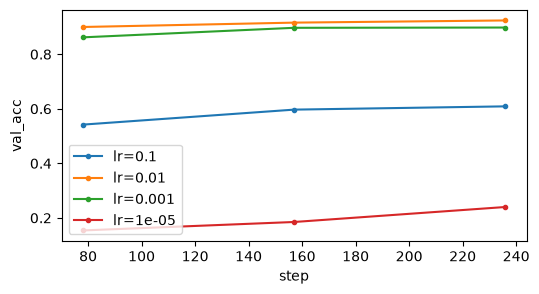

In [7]:
plot_metric("val_acc", ["lr=0.1", "lr=0.01", "lr=0.001", "lr=1e-05"])

In TensorBoard, tick and untick runs in the left panel to compare them. Each run's folder also has an `hparams.yaml` with its `lr` and `hidden`, which `save_hyperparameters()` recorded, so you can always tell what a run was.

### ✏️ Exercise 4: your turn, a small model vs a big one (≈8 min)

1. Finish `TrainAccNN`, a child of `LoggedNN`. Its `training_step` does what `LoggedNN.training_step` does, **and** also logs `"train_acc"`, the batch accuracy, computed the same way as `val_acc`.
2. Train two models with `train_run`, both with `lr=1e-3`:
   - `TrainAccNN(hidden=10)` with `version="hidden=10"`
   - `TrainAccNN(hidden=200)` with `version="hidden=200"`
3. In TensorBoard (or with `plot_metric`), compare `train_acc` and `val_acc` for the two runs. Which model is better? Which has the bigger gap between train and validation?

In [8]:
class TrainAccNN(LoggedNN):
    def training_step(self, batch, batch_idx):
        x, y = batch
        scores = self(x)
        loss = F.cross_entropy(scores, y)
        self.log("train_loss", loss)
        self.log("train_acc", (scores.argmax(dim=1) == y).float().mean())
        return loss


for hidden in [10, 200]:
    print(f"hidden={hidden}: val_acc={train_run(TrainAccNN(hidden=hidden), version=f'hidden={hidden}'):.3f}")

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Sanity Checking DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

Sanity Checking DataLoader 0:  50%|█████     | 1/2 [00:00<00:00, 857.56it/s]

Sanity Checking DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 695.86it/s]

Training: |          | 0/? [00:00<?, ?it/s]

... (1,020 outputs left out)

Epoch 2: 100%|██████████| 79/79 [00:00<00:00, 537.74it/s, v_num==200, val_loss=0.292, val_acc=0.912]

Epoch 2: 100%|██████████| 79/79 [00:00<00:00, 536.73it/s, v_num==200, val_loss=0.292, val_acc=0.912]

Epoch 2: 100%|██████████| 79/79 [00:00<00:00, 536.10it/s, v_num==200, val_loss=0.292, val_acc=0.912]

hidden=200: val_acc=0.912


✅ val_acc: hidden=10 → 0.850, hidden=200 → 0.912


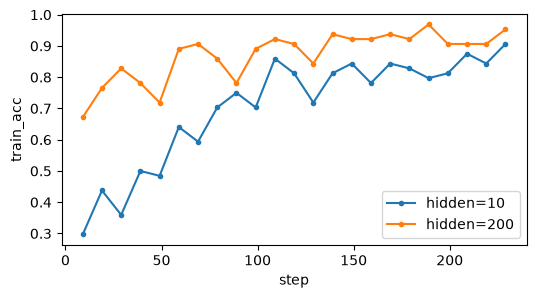

In [9]:
# --- Check (do not edit) ---
for v in ["hidden=10", "hidden=200"]:
    assert os.path.isdir(os.path.join(LOG_DIR, RUN_ID, v)), f"Finish the exercise above first ☝️ (no run called {v!r} yet)"
    assert read_scalars(v, "train_acc"), f"Run {v!r} has no 'train_acc'. Does training_step call self.log('train_acc', ...)?"
small, big = read_scalars("hidden=10", "val_acc")[-1][1], read_scalars("hidden=200", "val_acc")[-1][1]
assert big > small, "hidden=200 should end up more accurate than hidden=10. Did you swap the two?"
print(f"✅ val_acc: hidden=10 → {small:.3f}, hidden=200 → {big:.3f}")
plot_metric("train_acc", ["hidden=10", "hidden=200"])

## Bonus (if time): log images, not just numbers

`self.logger.experiment` is the raw TensorBoard writer. The course's `model.py` uses it to log a grid of training images. Here we log the validation digits the model gets **wrong**. They appear in TensorBoard's **Images** tab, one slider position per epoch.

In [10]:
class MistakesNN(LoggedNN):
    def validation_step(self, batch, batch_idx):
        super().validation_step(batch, batch_idx)  # keep val_loss and val_acc from the parent
        if batch_idx == 0:
            x, y = batch
            wrong = self(x).argmax(dim=1) != y
            images = x[wrong][:16].reshape(-1, 1, 28, 28)
            self.logger.experiment.add_images("val_mistakes", images, self.current_epoch)


train_run(MistakesNN(), version="mistakes")

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Sanity Checking DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

Sanity Checking DataLoader 0:  50%|█████     | 1/2 [00:00<00:00, 479.13it/s]

Sanity Checking DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 523.99it/s]

Training: |          | 0/? [00:00<?, ?it/s]

... (505 outputs left out)

Epoch 2: 100%|██████████| 79/79 [00:00<00:00, 651.37it/s, v_num=akes, val_loss=0.368, val_acc=0.899]

Epoch 2: 100%|██████████| 79/79 [00:00<00:00, 649.90it/s, v_num=akes, val_loss=0.368, val_acc=0.899]

Epoch 2: 100%|██████████| 79/79 [00:00<00:00, 648.77it/s, v_num=akes, val_loss=0.368, val_acc=0.899]

0.8989999890327454

## Wrap-up: you can now read the course's `train.py`

Open `lec5/train.py`. Every line in it is something you used today:

| `lec5/train.py` | Today |
|---|---|
| `TensorBoardLogger("tb_logs", name=RUN_ID, version=mode)` | `train_run`'s logger: one folder per run |
| `model = build_model(mode)` → a `pl.LightningModule` child | `LitNN`, `LoggedNN` (03, 04) |
| `MnistDataModule(...)` | `SmallMnistDataModule` (03) |
| `pl.Trainer(..., callbacks=[EarlyStopping(monitor="val_loss"), ...])` | Trainer arguments switch plumbing on; `monitor=` reads what `self.log` wrote |
| `trainer.fit` → `trainer.validate` → `trainer.test` | They call your `*_step` hooks (03) |
| `torch.save(model.encoder.state_dict(), ...)` | Composition: `encoder` is a module stored on `self` (01, 02) |

🔄 **Checkpoint:** run `git pull --no-edit` to get `tutoring/session01/solutions/04_tensorboard.ipynb`.